In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 파일명은 실제 업로드한 파일명으로 수정
df = pd.read_csv('마스터_A_동.csv')

print("데이터 크기:", df.shape)
print("\n컬럼 목록")
for col in df.columns:
    print(col)

df.head()

In [ ]:
# ============================================
# STEP 2. 수요 필터
# 방문 OR 외국인 카드 결제건수 하위 25%
# ============================================

# 하위 25% 기준값
visit_cut = df['방문'].quantile(0.25)
pay_cut = df['건수_음식소매'].quantile(0.25)

# 각각 기준 통과 여부
df['방문_통과'] = (df['방문'] > visit_cut).astype(int)
df['결제_통과'] = (df['건수_음식소매'] > pay_cut).astype(int)

# 둘 중 하나라도 통과하면 수요 있음
df['수요필터_통과'] = (
    (df['방문_통과'] == 1) |
    (df['결제_통과'] == 1)
).astype(int)

print("방문 하위 25% 기준값:", round(visit_cut))
print("결제건수 하위 25% 기준값:", round(pay_cut))

print("\n[수요 필터 결과]")
print(df['수요필터_통과'].value_counts())

print("\n[최종 제외 지역]")
print(
    df.loc[
        df['수요필터_통과'] == 0,
        ['행정동명', '방문', '건수_음식소매']
    ]
)

In [ ]:
# ============================================
# STEP 3. 수요 필터 통과 지역만 추출
# ============================================

df_demand = df[
    df['수요필터_통과'] == 1
].copy()

print("전체 지역:", len(df))
print("수요 필터 통과:", len(df_demand))

df_demand[
    ['행정동명', '방문', '건수_음식소매',
     'QR가맹률_음식소매', 'QR실사용률_음식소매']
].head(10)

In [ ]:
# ============================================
# STEP 4. 수요 필터 통과 37개 동 → QR 공백 계산
# ============================================

# QR 가맹률 중앙값
qr_median = df_demand['QR가맹률_음식소매'].median()

# QR 공백률 = 1 - QR 가맹률
df_demand['QR공백률_음식소매'] = (
    1 - df_demand['QR가맹률_음식소매']
)

# 중앙값 기준 QR 부족 / 충분 분류
df_demand['QR분류'] = df_demand['QR가맹률_음식소매'].apply(
    lambda x: 'QR 부족' if x < qr_median else 'QR 충분'
)

# 보기 편하게 % 변환
df_demand['QR가맹률_pct'] = (
    df_demand['QR가맹률_음식소매'] * 100
)

df_demand['QR공백률_pct'] = (
    df_demand['QR공백률_음식소매'] * 100
)

df_demand['QR실사용률_pct'] = (
    df_demand['QR실사용률_음식소매'] * 100
)

# QR 공백이 큰 순서로 순위
df_demand['QR공백순위'] = (
    df_demand['QR공백률_음식소매']
    .rank(ascending=False, method='min')
    .astype(int)
)

print("수요 필터 통과 지역:", len(df_demand))
print("QR가맹률 중앙값:", round(qr_median * 100, 2), "%")

print("\n[QR 분류]")
print(df_demand['QR분류'].value_counts())

qr_result = df_demand[
    [
        '행정동코드',
        '행정동명',
        '방문',
        '건수_음식소매',
        'QR가맹률_pct',
        'QR공백률_pct',
        'QR실사용률_pct',
        'QR분류',
        'QR공백순위'
    ]
].sort_values('QR공백순위')

qr_result.head(15)

In [ ]:
# ============================================
# STEP 4-1. QR가맹률 중앙값 vs 평균값 비교
# 수요 필터 통과 37개 동 기준
# ============================================

qr_median = df_demand['QR가맹률_음식소매'].median()
qr_mean = df_demand['QR가맹률_음식소매'].mean()

print("수요 필터 통과 지역:", len(df_demand))
print("QR가맹률 중앙값:", round(qr_median * 100, 2), "%")
print("QR가맹률 평균값:", round(qr_mean * 100, 2), "%")


# 중앙값 기준 분류
df_demand['QR분류_중앙값'] = df_demand['QR가맹률_음식소매'].apply(
    lambda x: 'QR 부족' if x < qr_median else 'QR 충분'
)

# 평균값 기준 분류
df_demand['QR분류_평균'] = df_demand['QR가맹률_음식소매'].apply(
    lambda x: 'QR 부족' if x < qr_mean else 'QR 충분'
)

print("\n[중앙값 기준]")
print(df_demand['QR분류_중앙값'].value_counts())

print("\n[평균값 기준]")
print(df_demand['QR분류_평균'].value_counts())


# 기준에 따라 분류가 달라지는 동 확인
changed = df_demand[
    df_demand['QR분류_중앙값'] != df_demand['QR분류_평균']
][[
    '행정동명',
    'QR가맹률_음식소매',
    'QR분류_중앙값',
    'QR분류_평균'
]].copy()

changed['QR가맹률(%)'] = (
    changed['QR가맹률_음식소매'] * 100
).round(2)

changed = changed[
    ['행정동명', 'QR가맹률(%)', 'QR분류_중앙값', 'QR분류_평균']
].sort_values('QR가맹률(%)')

print("\n분류가 달라지는 동 수:", len(changed))
changed

In [ ]:
# ============================================
# STEP 4. QR 공백 계산 + 중앙값 기준 분류
# ============================================

# 수요 필터 통과 37개 동의 QR가맹률 중앙값
qr_median = df_demand['QR가맹률_음식소매'].median()

# QR 공백률
df_demand['QR공백률_음식소매'] = 1 - df_demand['QR가맹률_음식소매']

# 중앙값 기준 QR 부족/충분
df_demand['QR분류'] = np.where(
    df_demand['QR가맹률_음식소매'] < qr_median,
    'QR 부족',
    'QR 충분'
)

# 보기 편하게 % 변환
df_demand['QR가맹률_pct'] = df_demand['QR가맹률_음식소매'] * 100
df_demand['QR공백률_pct'] = df_demand['QR공백률_음식소매'] * 100

print("QR가맹률 중앙값:", round(qr_median * 100, 2), "%")
print("동등한 QR공백률:", round((1 - qr_median) * 100, 2), "%")

print("\n[QR 분류 결과]")
print(df_demand['QR분류'].value_counts())

In [ ]:
# ============================================
# STEP 5. QR 공백 순위
# ============================================

df_demand['QR공백순위'] = (
    df_demand['QR공백률_음식소매']
    .rank(ascending=False, method='min')
    .astype(int)
)

qr_result = df_demand[[
    '행정동코드',
    '행정동명',
    '방문',
    '건수_음식소매',
    'QR가맹률_pct',
    'QR공백률_pct',
    'QR분류',
    'QR공백순위'
]].sort_values('QR공백순위').reset_index(drop=True)

# QR 부족 지역만
qr_shortage = qr_result[
    qr_result['QR분류'] == 'QR 부족'
].copy()

print("QR 부족 지역 수:", len(qr_shortage))

qr_shortage

In [ ]:
# ============================================
# STEP 6-1. 한글 폰트 설정
# ============================================

!apt-get -qq install fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

fm.fontManager.addfont(
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

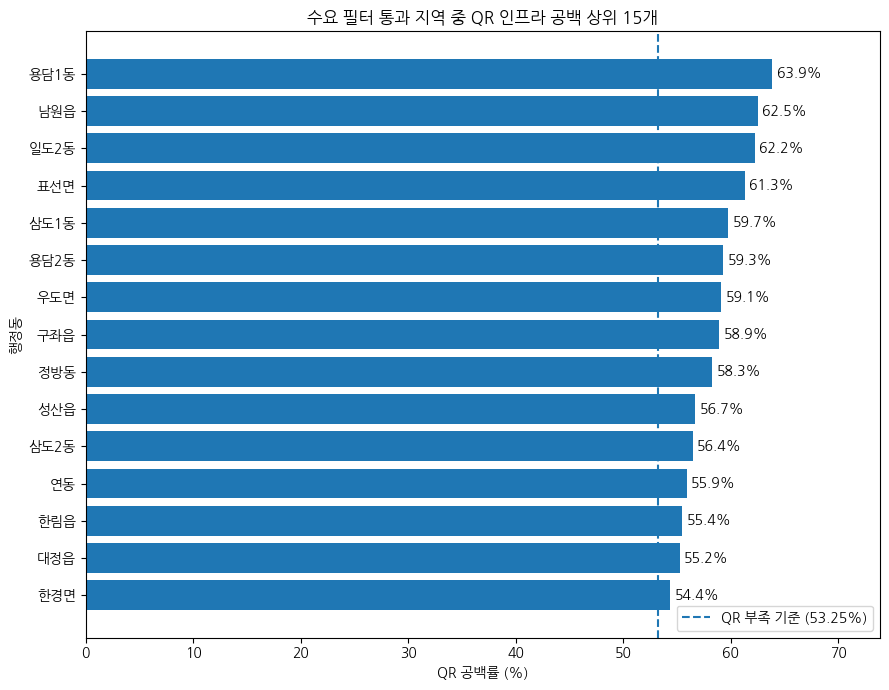

In [ ]:
# ============================================
# STEP 6-2. QR 공백 상위 15개 시각화
# ============================================

top15 = (
    qr_result
    .head(15)
    .sort_values('QR공백률_pct')
)

plt.figure(figsize=(9, 7))

bars = plt.barh(
    top15['행정동명'],
    top15['QR공백률_pct']
)

# 막대 끝에 공백률 표시
for bar, value in zip(bars, top15['QR공백률_pct']):
    plt.text(
        value + 0.4,
        bar.get_y() + bar.get_height()/2,
        f'{value:.1f}%',
        va='center'
    )

# 중앙값 기준 QR 공백 임계값
gap_threshold = (1 - qr_median) * 100

plt.axvline(
    gap_threshold,
    linestyle='--',
    linewidth=1.5,
    label=f'QR 부족 기준 ({gap_threshold:.2f}%)'
)

plt.xlabel('QR 공백률 (%)')
plt.ylabel('행정동')
plt.title('수요 필터 통과 지역 중 QR 인프라 공백 상위 15개')

plt.legend()
plt.xlim(0, top15['QR공백률_pct'].max() + 10)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# STEP 7. QR 부족 지역 18개 전체 확인
# ============================================

qr_shortage = (
    df_demand[df_demand['QR분류'] == 'QR 부족']
    [
        [
            '행정동명',
            'QR가맹률_pct',
            'QR공백률_pct',
            'QR공백순위'
        ]
    ]
    .sort_values('QR공백순위')
    .reset_index(drop=True)
)

# 소수점 둘째 자리까지
qr_shortage['QR가맹률_pct'] = qr_shortage['QR가맹률_pct'].round(2)
qr_shortage['QR공백률_pct'] = qr_shortage['QR공백률_pct'].round(2)

print("QR 부족 지역 수:", len(qr_shortage))
print("QR 부족 기준: QR가맹률 <", round(qr_median * 100, 2), "%")

qr_shortage

In [ ]:
# ============================================
# STEP 8. QR 공백 최종 분석표 저장
# ============================================

qr_final = df_demand[[
    '행정동코드',
    '행정동명',
    '방문',
    '건수_음식소매',
    'QR가맹률_음식소매',
    'QR공백률_음식소매',
    'QR분류',
    'QR공백순위'
]].copy()

# 보기 편하게 % 단위로 변환
qr_final['QR가맹률'] = (
    qr_final['QR가맹률_음식소매'] * 100
).round(2)

qr_final['QR공백률'] = (
    qr_final['QR공백률_음식소매'] * 100
).round(2)

# 기존 소수형 변수 제거
qr_final = qr_final.drop(
    columns=[
        'QR가맹률_음식소매',
        'QR공백률_음식소매'
    ]
)

# 컬럼명 정리
qr_final = qr_final.rename(
    columns={
        '건수_음식소매': '음식소매_결제건수'
    }
)

# QR 공백이 큰 순으로 정렬
qr_final = (
    qr_final
    .sort_values('QR공백순위')
    .reset_index(drop=True)
)

# 저장
file_path = '/content/읍면동_QR공백_진단_최종.csv'

qr_final.to_csv(
    file_path,
    index=False,
    encoding='utf-8-sig'
)

print("저장 완료:", file_path)
print("지역 수:", len(qr_final))

qr_final